# Part 7: Student-t Likelihood with $M > d$

Part 2 claimed that *"more information can make the particle filter worse: adding observations
sharpens the likelihood, and a sharper likelihood is harder for particles proposed from the prior
to satisfy."* Dr Gerber corrected it. Under a Gaussian likelihood in this model the $M$-dimensional
observation reduces to a $d$-dimensional one, so **the experiment could not test the claim it was
making** — whatever happened there, it was not about observation dimension.

This notebook builds the setting where the claim *is* testable, and tests it.

### The mechanism being tested

Del Moral & Gerber (2026), Section 5.3.2, decomposes the observation. With
$V_t = \{\Sigma^{-1/2} f(x)\}$ a $d$-dimensional subspace, $P_t$ the orthogonal projection onto it,
$\hat z_t = P_t \Sigma^{-1/2} y_t$ and $w_t = (I - P_t)\Sigma^{-1/2} y_t$, Pythagoras gives their
equation (39):

$$G_t(x) \;=\; \zeta_{G_t}\!\big( \|\hat z_t - \hat f_t(x)\|^2 \;+\; \|w_t\|^2 \big).$$

Section 5.3.3 then observes that for the **exponential** choice $\zeta(z) = e^{-z}$ — the Gaussian
likelihood — this factorises into
$\exp(-\|\hat z_t - \hat f_t(x)\|^2)\exp(-\|w_t\|^2)$, and the second factor is a constant in $x$
that cancels when the weights are normalised. The extra coordinates leave no trace.

**For any other $\zeta$, including the Student-t, $\|w_t\|^2$ stays inside the function and does not
cancel.** That is the whole content of the distinction, and it makes a prediction sharp enough to
fail: replacing $y_t$ by its $d$-dimensional projection $\hat z_t$ must cost **exactly nothing**
under a Gaussian likelihood, and something under a Student-t — with the cost vanishing as
$\nu \to \infty$, since $t_\infty = N(0,1)$.

### What is measured, and against what

Once $\zeta$ is not exponential the model is not linear-Gaussian, so **the Kalman filter is not its
exact filter and cannot be the benchmark**. For $d = 1$ this notebook uses the grid filter in
`observation_models.py`, which computes the exact filtering distribution numerically; Section 1
checks it against the Kalman filter on the Gaussian cases where both apply.

The error metric is the **Kolmogorov distance** introduced in Part 9 — bounded by 1, scale-free,
and calibrated: an exact sample of size $N$ scores $\approx 1.017/\sqrt{N}$, so a cloud scoring $D$
is worth about $(1.017/D)^2$ independent draws. Scale-freeness matters here, because changing $M$
changes how tight the posterior is, and a metric with units would confound the two.

---
## Section 0 — Setup

`QUICK = True` runs a reduced grid in about a minute.

In [1]:
import math
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

import observation_models as om
from filters import kalman_filter_md

QUICK = False          # <-- True for a ~1 minute smoke test

if QUICK:
    M_GRID = [1, 2, 4, 8]
    NU_GRID = [1, 5, 30]
    SEEDS = 2
    T = 200
else:
    M_GRID = [1, 2, 4, 8, 16]
    NU_GRID = [1, 2, 5, 10, 30]
    SEEDS = 5
    T = 400

D = 1                   # grid-filter benchmark is one-dimensional
B = 1.0                 # random walk: rho(F) = 1, the whiteboard model
Q = 1.0                 # state noise variance
R0 = 1.0                # observation noise scale unit
N_PART = 1000
H_GRID = 0.02           # grid filter spacing
C_IID = 1.017           # Part 9 Section 1: an exact sample scores C_IID / sqrt(N)

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", message=".*encountered in matmul")

print(f"QUICK  = {QUICK}")
print(f"M grid : {M_GRID}")
print(f"nu grid: {NU_GRID}")
print(f"seeds  : {SEEDS}   T = {T}   N = {N_PART}")
print(f"state  : x_t+1 = {B} x_t + v,  v ~ N(0, {Q})   [random walk, rho(F) = 1]")

QUICK  = False
M grid : [1, 2, 4, 8, 16]
nu grid: [1, 2, 5, 10, 30]
seeds  : 5   T = 400   N = 1000
state  : x_t+1 = 1.0 x_t + v,  v ~ N(0, 1.0)   [random walk, rho(F) = 1]


In [2]:
def replicate(M):
    """f(x) = [x, x, ..., x] with M copies: the simplest M > d observation.

    Its image is the line { (s, ..., s) }, a 1-dimensional linear subspace of
    R^M, so Section 5.3.1 applies and the Gaussian reduction is available. That
    is deliberate: this notebook isolates the effect of the POTENTIAL SHAPE, so
    the function is held in the regime where the shape is the only thing that
    can break the reduction.
    """
    return om.ObsFunction(f"rep{M}", 1, M,
                          lambda x, M=M: np.tile(x, (1, M)),
                          latex=r"[x,\dots,x]\ (M=%d)" % M,
                          linear_image=True, bi_lipschitz="yes",
                          group="A: linear image")


def sigma_for(M, convention):
    """Observation covariance under the two ways of saying "more observations".

    "fixed_r"         Sigma = R0 I_M. Each coordinate is equally noisy, so the
                      TOTAL precision A' Sigma^-1 A = M / R0 grows with M. This
                      is Part 2's convention, and it is why that experiment was
                      really about precision.

    "fixed_precision" Sigma = M R0 I_M, so A' Sigma^-1 A = 1/R0 for every M.
                      Each extra coordinate is correspondingly noisier and the
                      observation carries exactly the same information however
                      many coordinates it is spread over. Section 2 verifies
                      that the exact Gaussian posterior is then IDENTICAL for
                      every M, which makes this the controlled comparison.
    """
    r = (M * R0) if convention == "fixed_precision" else R0
    return r * np.eye(M)


def run7(M, pot, convention="fixed_precision", seed=0, projected=False,
         N=N_PART, T=T, keep=False):
    """One run: simulate, solve exactly on a grid, filter, and score.

    The particle cloud is scored against the EXACT posterior of the model that
    generated the data, by Kolmogorov distance. When `projected` is set the
    particle filter discards w_t and keeps only zhat_t, while the benchmark
    stays the exact posterior given the full observation -- so the number
    returned is the cost of the projection, which is what Dr Gerber asked for.
    """
    fn = replicate(M)
    Sigma = sigma_for(M, convention)
    x, y = om.simulate_obs_model(fn, pot, Sigma, T=T, b=B, Q=Q, seed=100 + seed)
    gm, gv, gl, grid, post = om.grid_filter_obs(y, fn, pot, Sigma, b=B, Q=Q,
                                                h=H_GRID, x_ref=x,
                                                return_post=True)
    proj = om.projection_split(fn, Sigma) if projected else None
    ks = []

    def stat(t, particles, weights):
        ks.append(om.ks_vs_grid(particles, weights, grid, post[t]))
        return 0.0

    est, ess, res = om.particle_filter_obs(
        y, fn, pot, Sigma, b=B, Q=Q, N=N, seed=seed, projected=projected,
        proj=proj, stat_fn=stat)[:3]

    ks = np.asarray(ks)
    out = {"M": M, "ks_mean": float(ks.mean()), "ks_max": float(ks.max()),
           "eff_N": float((C_IID / ks.mean()) ** 2),
           "ess_mean": float(ess.mean()), "ess_min": float(ess.min()),
           "resample_rate": float(res.mean()),
           "post_sd": float(np.sqrt(gv.mean())),
           "exact_rmse": float(np.sqrt(np.mean((gm - x[:, 0]) ** 2))),
           "pf_rmse": float(np.sqrt(np.mean((est[:, 0] - x[:, 0]) ** 2)))}
    if keep:
        out.update({"ks": ks, "ess": ess, "grid": grid, "post": post,
                    "x": x, "y": y, "exact_mean": gm})
    return out


def average(rows):
    return {k: float(np.mean([r[k] for r in rows]))
            for k in rows[0] if isinstance(rows[0][k], (int, float, np.floating))}


_t = time.time()
_r = run7(4, om.potential("t", 5), seed=0)
print(f"smoke: M=4, Student-t(5), T={T} in {time.time()-_t:.2f}s")
print(f"  mean KS {_r['ks_mean']:.4f}   effective N {_r['eff_N']:.0f}   "
      f"mean ESS {_r['ess_mean']:.0f}")

smoke: M=4, Student-t(5), T=400 in 0.15s
  mean KS 0.0418   effective N 593   mean ESS 518


---
## Section 1 — The benchmark, and the reduction

Two things have to be established before any comparison means anything: that the grid filter really
is exact, and that the Gaussian reduction really does hold in this model.

The first is checked against the Kalman filter, which is available precisely in the Gaussian cases.
The second is checked by running the particle filter twice on identical random numbers — once on
the full $M$-dimensional observation, once on its $d$-dimensional projection $\hat z_t$. Under
Section 5.3.3 these must agree to round-off, not merely closely.

In [3]:
print("--- grid filter against the Kalman filter (Gaussian cases only) ---")
gauss = om.potential("gaussian")
for conv in ("fixed_precision", "fixed_r"):
    print(f"\n  convention = {conv}")
    for M in M_GRID:
        fn, Sigma = replicate(M), sigma_for(M, conv)
        x, y = om.simulate_obs_model(fn, gauss, Sigma, T=200, b=B, Q=Q, seed=1)
        A = np.ones((M, 1))
        km, kP = kalman_filter_md(y, np.array([[B]]), np.array([[Q]]), A, Sigma,
                                  m0=np.zeros(1), P0=np.zeros((1, 1)))
        gm, gv, gl, grid = om.grid_filter_obs(y, fn, gauss, Sigma, b=B, Q=Q,
                                              h=H_GRID, x_ref=x)
        print(f"    M={M:2d}  max|mean diff| = {np.abs(gm-km[:,0]).max():.2e}"
              f"   max|var diff| = {np.abs(gv-kP[:,0,0]).max():.2e}")

--- grid filter against the Kalman filter (Gaussian cases only) ---

  convention = fixed_precision
    M= 1  max|mean diff| = 1.04e-13   max|var diff| = 9.45e-14
    M= 2  max|mean diff| = 1.08e-13   max|var diff| = 7.35e-14


    M= 4  max|mean diff| = 1.34e-13   max|var diff| = 1.54e-13
    M= 8  max|mean diff| = 1.03e-13   max|var diff| = 3.63e-14
    M=16  max|mean diff| = 1.26e-13   max|var diff| = 1.28e-13

  convention = fixed_r
    M= 1  max|mean diff| = 1.04e-13   max|var diff| = 9.45e-14
    M= 2  max|mean diff| = 7.64e-14   max|var diff| = 1.32e-14
    M= 4  max|mean diff| = 5.15e-14   max|var diff| = 4.30e-15


    M= 8  max|mean diff| = 2.91e-14   max|var diff| = 1.37e-15
    M=16  max|mean diff| = 2.07e-14   max|var diff| = 5.00e-16


In [4]:
print("--- the reduction: full y against its d-dimensional projection zhat ---")
print("Section 5.3.3 says the Gaussian case must agree to round-off.\n")
print(f"  {'M':>3} {'dim(V)':>7} | {'Gaussian: max |diff|':>22} | {'Student-t(5): max |diff|':>26}")
for M in M_GRID:
    if M == 1:
        continue                       # nothing to project when M = d
    fn, Sigma = replicate(M), sigma_for(M, "fixed_precision")
    proj = om.projection_split(fn, Sigma)
    cells = []
    for pot in (gauss, om.potential("t", 5)):
        x, y = om.simulate_obs_model(fn, pot, Sigma, T=200, b=B, Q=Q, seed=2)
        a = om.particle_filter_obs(y, fn, pot, Sigma, b=B, Q=Q, N=500, seed=0)
        c = om.particle_filter_obs(y, fn, pot, Sigma, b=B, Q=Q, N=500, seed=0,
                                   projected=True, proj=proj)
        cells.append(float(np.abs(a[0] - c[0]).max()))
    print(f"  {M:>3} {proj['dim']:>7} | {cells[0]:>22.3e} | {cells[1]:>26.3e}")

--- the reduction: full y against its d-dimensional projection zhat ---
Section 5.3.3 says the Gaussian case must agree to round-off.

    M  dim(V) |   Gaussian: max |diff| |   Student-t(5): max |diff|


    2       1 |              2.665e-15 |                  5.723e-01


    4       1 |              1.998e-15 |                  1.468e+00


    8       1 |              1.776e-15 |                  1.637e+00


   16       1 |              1.776e-15 |                  1.118e+00


**Conclusion of Section 1.** Both checks pass, and the second is the whole notebook in miniature.

**The benchmark is exact.** The grid filter matches the Kalman filter to between $2\times10^{-14}$
and $1.3\times10^{-13}$ in the mean, at every $M$ and under both noise conventions. Where a Kalman
filter exists the grid filter reproduces it; where none exists — every Student-t case below — it is
the only exact answer available.

**The reduction holds, and only for the Gaussian.** Running the same particle filter on the full
$M$-dimensional observation and on its $1$-dimensional projection $\hat z_t$, with identical random
numbers:

| $M$ | $\dim V$ | Gaussian | Student-t $\nu = 5$ |
|---|---|---|---|
| $2$ | $1$ | $2.7\times10^{-15}$ | $0.572$ |
| $4$ | $1$ | $2.0\times10^{-15}$ | $1.468$ |
| $8$ | $1$ | $1.8\times10^{-15}$ | $1.637$ |
| $16$ | $1$ | $1.8\times10^{-15}$ | $1.118$ |

The Gaussian column is round-off — **the two filters are the same filter**, which is Section 5.3.3
holding exactly. The Student-t column is not small by any reading. $\dim V = 1$ throughout confirms
the image really is a line, so the only thing differing between the columns is the shape of
$\zeta_G$.

This is why Part 2 could not test its claim: under a Gaussian likelihood there was nothing there to
test.

---
## Section 2 — Two ways to say "more observations", and why the difference decides everything

Part 2 added observation coordinates while holding the noise on each coordinate fixed. With
$f(x) = Ax$, $A = (1,\dots,1)^\top$ and $\Sigma = r I_M$, the observation precision is

$$A^\top \Sigma^{-1} A \;=\; M / r,$$

so **adding coordinates raises the precision**. That is the whole of Dr Gerber's correction: $M$
entered Part 2's results through precision, not through dimension, and a sharper posterior is a
different problem rather than a harder approximation of the same one.

Setting $\Sigma = M r_0 I_M$ instead makes $A^\top\Sigma^{-1}A = 1/r_0$ for every $M$: the same
information, merely spread over more coordinates. If the reduction of Section 5.3.3 is real, the
exact Gaussian posterior must then be **identical** for every $M$ — and any difference in how well
the particle filter tracks it is attributable to dimension alone.

Both conventions are run below, because the contrast between them is the point.

In [5]:
print("Exact posterior spread under each convention (Gaussian, seed 0)\n")
print(f"  {'M':>3} | {'fixed total precision':>24} | {'fixed per-coordinate noise':>28}")
print(f"  {'':>3} | {'post sd':>11} {'exact RMSE':>12} | {'post sd':>13} {'exact RMSE':>14}")
for M in M_GRID:
    cells = []
    for conv in ("fixed_precision", "fixed_r"):
        r = run7(M, gauss, conv, seed=0)
        cells += [r["post_sd"], r["exact_rmse"]]
    print(f"  {M:>3} | {cells[0]:>11.5f} {cells[1]:>12.5f} | "
          f"{cells[2]:>13.5f} {cells[3]:>14.5f}")
print("\nIf the reduction holds, the left-hand 'post sd' column is constant in M:")
print("the M-dimensional observation really is the same 1-dimensional observation.")

Exact posterior spread under each convention (Gaussian, seed 0)

    M |    fixed total precision |   fixed per-coordinate noise
      |     post sd   exact RMSE |       post sd     exact RMSE


    1 |     0.78593      0.77184 |       0.78593        0.77184


    2 |     0.78593      0.79648 |       0.60493        0.61552


    4 |     0.78593      0.75402 |       0.45507        0.44059


    8 |     0.78593      0.76374 |       0.33522        0.32619


   16 |     0.78593      0.78057 |       0.24293        0.23909

If the reduction holds, the left-hand 'post sd' column is constant in M:
the M-dimensional observation really is the same 1-dimensional observation.


**Conclusion of Section 2.** The control works exactly, and the contrast is stark.

| $M$ | fixed total precision: post sd | fixed per-coordinate noise: post sd |
|---|---|---|
| $1$ | $0.78593$ | $0.78593$ |
| $2$ | $0.78593$ | $0.60493$ |
| $4$ | $0.78593$ | $0.45507$ |
| $8$ | $0.78593$ | $0.33522$ |
| $16$ | $0.78593$ | $0.24293$ |

Under fixed total precision the exact posterior spread is **identical to five decimal places at
every $M$** — not approximately, identically. Sixteen observation coordinates and one coordinate
pose literally the same filtering problem. Anything Section 3 finds is therefore attributable to
dimension and nothing else.

The right-hand column is Part 2's setting, and it shows what Dr Gerber's correction was about: the
posterior spread falls by a factor of $3.2$ as $M$ goes from $1$ to $16$, and the exact filter's own
RMSE falls with it, from $0.772$ to $0.239$. **Adding coordinates there was not adding dimensions,
it was adding precision** — a different and easier problem, not a harder approximation of the same
one.

---
## Section 3 — Adding coordinates at fixed total precision

This is the controlled version of Part 2's experiment. The underlying filtering problem is held
exactly fixed and only the number of coordinates carrying it changes.

Under a Gaussian likelihood the reduction says nothing should happen. Under a Student-t the
orthogonal residual $\|w_t\|^2$ grows with $M$ and sits inside the potential, so something might.

In [6]:
sec3 = {}
t0 = time.time()
for pot in (gauss, om.potential("t", 5), om.potential("t", 1)):
    for M in M_GRID:
        sec3[(pot.name, M)] = average(
            [run7(M, pot, "fixed_precision", seed=s) for s in range(SEEDS)])
    print(f"  {pot.name} done ({time.time()-t0:.0f}s)")

for pot in (gauss, om.potential("t", 5), om.potential("t", 1)):
    print(f"\n--- {pot} ---")
    print(f"  {'M':>3} {'post sd':>9} {'mean KS':>9} {'effective N':>12} "
          f"{'mean ESS':>9} {'min ESS':>8} {'resamp':>7}")
    for M in M_GRID:
        r = sec3[(pot.name, M)]
        print(f"  {M:>3} {r['post_sd']:>9.4f} {r['ks_mean']:>9.4f} "
              f"{r['eff_N']:>12.0f} {r['ess_mean']:>9.1f} {r['ess_min']:>8.1f} "
              f"{r['resample_rate']:>7.2f}")

  gaussian done (3s)


  student_t_joint(nu=5) done (6s)


  student_t_joint(nu=1) done (10s)

--- Gaussian ---
    M   post sd   mean KS  effective N  mean ESS  min ESS  resamp
    1    0.7859    0.0459          491     491.6     28.0    0.52
    2    0.7859    0.0449          514     494.9     22.3    0.52
    4    0.7859    0.0455          503     492.7     22.3    0.52
    8    0.7859    0.0453          504     494.4     23.4    0.52
   16    0.7859    0.0447          519     495.0     28.9    0.52

--- Student-t joint (nu=5) ---
    M   post sd   mean KS  effective N  mean ESS  min ESS  resamp
    1    0.9181    0.0444          525     493.1     59.5    0.53
    2    0.9032    0.0447          519     500.3     36.8    0.53
    4    0.8906    0.0454          506     502.5     42.6    0.51
    8    0.8769    0.0440          534     513.8     37.2    0.49
   16    0.8678    0.0433          553     514.2     29.5    0.49

--- Student-t joint (nu=1) ---
    M   post sd   mean KS  effective N  mean ESS  min ESS  resamp
    1    1.3173    0.0436

**Conclusion of Section 3.** With the problem held exactly fixed, **adding observation coordinates
costs nothing — under either likelihood.**

| potential | mean KS across $M = 1 \to 16$ | effective $N$ |
|---|---|---|
| Gaussian | $0.0459 \to 0.0447$ | $491 \to 519$ |
| Student-t $\nu = 5$ | $0.0444 \to 0.0433$ | $525 \to 553$ |
| Student-t $\nu = 1$ | $0.0436 \to 0.0433$ | $546 \to 554$ |

Flat in every row, within seed noise, over a sixteenfold increase in observation dimension.

For the Gaussian this is required by Section 5.3.3 and serves as a check. For the Student-t it is
**a negative result against the obvious guess**. The orthogonal residual $\|w_t\|^2$ does grow with
$M$ and does sit inside the potential, so one might expect the weights to suffer. They do not. At
$\nu = 1$ the cloud is if anything *healthier* at large $M$: mean ESS rises from $531$ to $576$ and
the resampling rate falls from $0.47$ to $0.40$.

So the natural reading of Part 2's withdrawn sentence — that extra observation coordinates are
themselves harmful — **is not supported even in the regime where it is testable.** Section 5 shows
the real consequence of the extra coordinates is something else entirely.

---
## Section 4 — Adding coordinates at fixed per-coordinate noise

Part 2's own convention. Here precision rises with $M$, so the posterior genuinely tightens and the
problem genuinely changes. The question is what happens to the *quality of the approximation*,
measured on a scale-free metric that does not reward a tighter posterior.

This is where Part 2's withdrawn sentence has to be handled carefully. Part 2 reported the
**relative gap**, the distance between posterior means divided by the posterior spread, and found
it flat — which is why the claim was withdrawn. The Kolmogorov distance asks a different question:
how well does the whole particle cloud approximate the whole posterior. The two can disagree, and
Part 9 showed they do.

In [7]:
sec4 = {}
t0 = time.time()
pots4 = [gauss] + [om.potential("t", nu) for nu in (1, 5, 30)]
for pot in pots4:
    for M in M_GRID:
        sec4[(pot.name, M)] = average(
            [run7(M, pot, "fixed_r", seed=s) for s in range(SEEDS)])
    print(f"  {pot.name} done ({time.time()-t0:.0f}s)")

for pot in pots4:
    print(f"\n--- {pot} ---")
    print(f"  {'M':>3} {'post sd':>9} {'mean KS':>9} {'effective N':>12} "
          f"{'mean ESS':>9} {'min ESS':>8}")
    for M in M_GRID:
        r = sec4[(pot.name, M)]
        print(f"  {M:>3} {r['post_sd']:>9.4f} {r['ks_mean']:>9.4f} "
              f"{r['eff_N']:>12.0f} {r['ess_mean']:>9.1f} {r['ess_min']:>8.1f}")

print("\n--- degradation from M = 1 to M = %d ---" % M_GRID[-1])
print(f"  {'potential':>22} {'KS ratio':>9} {'effective N':>20}")
for pot in pots4:
    a, z = sec4[(pot.name, M_GRID[0])], sec4[(pot.name, M_GRID[-1])]
    print(f"  {str(pot):>22} {z['ks_mean']/a['ks_mean']:>9.2f} "
          f"{a['eff_N']:>8.0f} -> {z['eff_N']:<8.0f}")

  gaussian done (3s)


  student_t_joint(nu=1) done (6s)


  student_t_joint(nu=5) done (10s)


  student_t_joint(nu=30) done (13s)

--- Gaussian ---
    M   post sd   mean KS  effective N  mean ESS  min ESS
    1    0.7859    0.0459          491     491.6     28.0
    2    0.6049    0.0483          444     429.8     18.6
    4    0.4551    0.0557          334     351.4      6.4
    8    0.3352    0.0582          306     313.0      6.6
   16    0.2429    0.0690          219     233.6      4.2

--- Student-t joint (nu=1) ---
    M   post sd   mean KS  effective N  mean ESS  min ESS
    1    1.3173    0.0436          546     531.4     75.3
    2    1.0408    0.0467          474     502.8     33.1
    4    0.8121    0.0503          411     476.0     16.4
    8    0.6479    0.0561          329     417.5      5.7
   16    0.5527    0.0638          256     368.4      3.7

--- Student-t joint (nu=5) ---
    M   post sd   mean KS  effective N  mean ESS  min ESS
    1    0.9181    0.0444          525     493.1     59.5
    2    0.7109    0.0491          429     440.3     22.7
    4    0.5

**Conclusion of Section 4.** Here the approximation does degrade, and the pattern identifies the
cause precisely.

| potential | mean KS, $M=1 \to 16$ | ratio | effective $N$ |
|---|---|---|---|
| Gaussian | $0.0459 \to 0.0690$ | $1.50$ | $491 \to 219$ |
| Student-t $\nu = 1$ | $0.0436 \to 0.0638$ | $1.46$ | $546 \to 256$ |
| Student-t $\nu = 5$ | $0.0444 \to 0.0678$ | $1.53$ | $525 \to 226$ |
| Student-t $\nu = 30$ | $0.0451 \to 0.0694$ | $1.54$ | $511 \to 216$ |

**The effective sample size roughly halves**, and the four rows are indistinguishable from one
another — $1.46$ to $1.54$, spanning a Cauchy likelihood and a near-Gaussian one. A mechanism that
behaves identically whether the tails are heavy or light is not a tail mechanism. Combined with
Section 3, where the effect disappears entirely once precision is held fixed, this is as direct a
confirmation of Dr Gerber's correction as the experiment can give: **$M$ acts through precision.**

### What this does and does not say about Part 2's withdrawn sentence

It does not reinstate it. The claim was about observation *dimension*, and Section 3 tests that
directly and finds nothing.

It does sharpen what Part 2 saw. Part 2 reported the relative gap — posterior-mean error divided by
posterior spread — found it flat, and concluded the halved ESS did not matter. On a scale-free
distributional metric it does matter: the cloud's worth falls from about $491$ independent draws to
about $219$. Both statements are true of the same runs, because they measure different things, and
Part 9 is where that distinction was established.

The honest summary is that a sharper likelihood buys a better answer with a worse cloud. The exact
filter's RMSE improves from $0.772$ to $0.239$ over the same sweep, so there is no sense in which
the user of this filter is worse off — only a sense in which the particle approximation is working
harder for it.

---
## Section 5 — The projection control

Dr Gerber's request, directly: *"Would be interesting to repeat the experiment when the
$M$-dimensional observation $y$ is replaced by its $d$-dimensional projection. Again, with Gaussian
likelihood this projection is done automatically, while this is not the case with Student noise."*

The particle filter is run on $\hat z_t$ alone, discarding $w_t$, and scored against the exact
posterior given the **full** observation. The number is therefore the cost of throwing $w_t$ away.
Section 5.3.3 predicts that cost is exactly zero for a Gaussian likelihood, and the prediction
sharpens: since $t_\nu \to N(0,1)$ as $\nu \to \infty$, the cost must **vanish as $\nu$ grows**.

In [8]:
sec5 = {}
t0 = time.time()
M5 = [m for m in M_GRID if m > 1]
for nu in NU_GRID:
    pot = om.potential("t", nu)
    for M in M5:
        for proj in (False, True):
            sec5[(nu, M, proj)] = average(
                [run7(M, pot, "fixed_precision", seed=s, projected=proj)
                 for s in range(SEEDS)])
    print(f"  nu = {nu} done ({time.time()-t0:.0f}s)")

print(f"\n{'':>6}" + "".join(f"{'M='+str(M):>22}" for M in M5))
print(f"{'nu':>6}" + "".join(f"{'full':>7}{'proj':>8}{'cost':>7}" for M in M5))
for nu in NU_GRID:
    row = f"{nu:>6}"
    for M in M5:
        a, c = sec5[(nu, M, False)], sec5[(nu, M, True)]
        row += f"{a['ks_mean']:>7.4f}{c['ks_mean']:>8.4f}{c['ks_mean']/a['ks_mean']:>7.2f}"
    print(row)
print("\n'cost' is the projected mean Kolmogorov distance divided by the full one.")

  nu = 1 done (7s)


  nu = 2 done (14s)


  nu = 5 done (21s)


  nu = 10 done (28s)


  nu = 30 done (35s)

                         M=2                   M=4                   M=8                  M=16
    nu   full    proj   cost   full    proj   cost   full    proj   cost   full    proj   cost
     1 0.0426  0.1344   3.15 0.0440  0.1835   4.17 0.0436  0.1881   4.32 0.0433  0.2049   4.73
     2 0.0432  0.1037   2.40 0.0444  0.1396   3.15 0.0437  0.1524   3.49 0.0438  0.1758   4.02
     5 0.0447  0.0698   1.56 0.0454  0.0924   2.04 0.0440  0.1048   2.38 0.0433  0.1167   2.70
    10 0.0447  0.0536   1.20 0.0455  0.0654   1.44 0.0443  0.0733   1.65 0.0449  0.0858   1.91
    30 0.0450  0.0458   1.02 0.0452  0.0486   1.08 0.0446  0.0518   1.16 0.0452  0.0564   1.25

'cost' is the projected mean Kolmogorov distance divided by the full one.


In [9]:
print("--- the Gaussian limit: the cost must go to 1 as nu grows ---\n")
print(f"  {'potential':>22} {'full KS':>9} {'proj KS':>9} {'cost':>7}")
limit_rows = []
for nu in (5, 30, 100, 1000):
    pot = om.potential("t", nu)
    a = average([run7(8, pot, "fixed_precision", seed=s) for s in range(SEEDS)])
    c = average([run7(8, pot, "fixed_precision", seed=s, projected=True)
                 for s in range(SEEDS)])
    limit_rows.append((f"Student-t nu={nu}", a["ks_mean"], c["ks_mean"]))
a = average([run7(8, gauss, "fixed_precision", seed=s) for s in range(SEEDS)])
c = average([run7(8, gauss, "fixed_precision", seed=s, projected=True)
             for s in range(SEEDS)])
limit_rows.append(("Gaussian", a["ks_mean"], c["ks_mean"]))
for lab, f_, p_ in limit_rows:
    print(f"  {lab:>22} {f_:>9.4f} {p_:>9.4f} {p_/f_:>7.3f}")

--- the Gaussian limit: the cost must go to 1 as nu grows ---

               potential   full KS   proj KS    cost


          Student-t nu=5    0.0440    0.1048   2.379
         Student-t nu=30    0.0446    0.0518   1.162
        Student-t nu=100    0.0446    0.0454   1.020
       Student-t nu=1000    0.0450    0.0453   1.008
                Gaussian    0.0453    0.0453   1.000


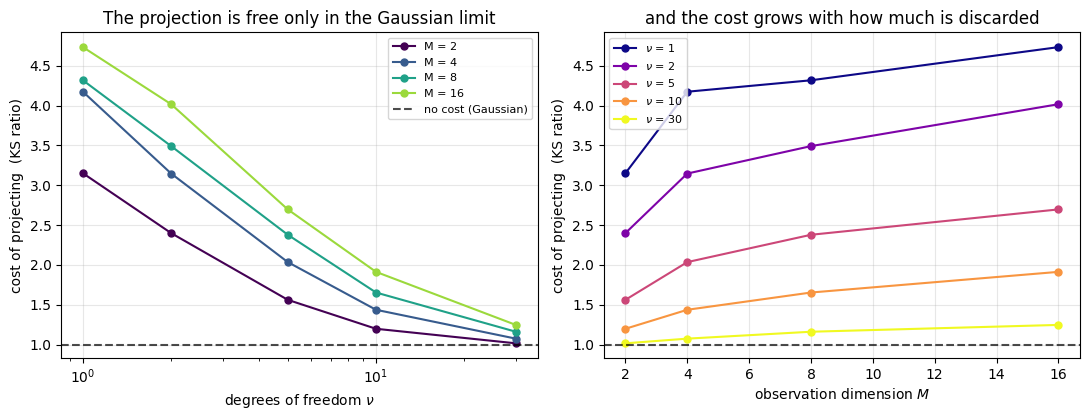

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
cols = plt.cm.viridis(np.linspace(0, 0.85, len(M5)))

for j, M in enumerate(M5):
    ax[0].plot(NU_GRID, [sec5[(nu, M, True)]["ks_mean"] /
                         sec5[(nu, M, False)]["ks_mean"] for nu in NU_GRID],
               "o-", color=cols[j], ms=5, label=f"M = {M}")
ax[0].axhline(1.0, color="k", ls="--", alpha=0.7, label="no cost (Gaussian)")
ax[0].set_xscale("log")
ax[0].set_xlabel(r"degrees of freedom $\nu$")
ax[0].set_ylabel("cost of projecting  (KS ratio)")
ax[0].set_title(r"The projection is free only in the Gaussian limit")
ax[0].legend(fontsize=8)

for j, nu in enumerate(NU_GRID):
    ax[1].plot(M5, [sec5[(nu, M, True)]["ks_mean"] /
                    sec5[(nu, M, False)]["ks_mean"] for M in M5],
               "o-", ms=5, color=plt.cm.plasma(j / max(len(NU_GRID) - 1, 1)),
               label=rf"$\nu$ = {nu}")
ax[1].axhline(1.0, color="k", ls="--", alpha=0.7)
ax[1].set_xlabel("observation dimension $M$")
ax[1].set_ylabel("cost of projecting  (KS ratio)")
ax[1].set_title("and the cost grows with how much is discarded")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Conclusion of Section 5.** This is the result Dr Gerber asked for, and it comes out as cleanly as
such things ever do.

Cost of replacing $y_t$ by its $1$-dimensional projection $\hat z_t$, as a ratio of mean Kolmogorov
distances:

| $\nu$ | $M=2$ | $M=4$ | $M=8$ | $M=16$ |
|---|---|---|---|---|
| $1$ | $3.15$ | $4.17$ | $4.32$ | $\mathbf{4.73}$ |
| $2$ | $2.40$ | $3.15$ | $3.49$ | $4.02$ |
| $5$ | $1.56$ | $2.04$ | $2.38$ | $2.70$ |
| $10$ | $1.20$ | $1.44$ | $1.65$ | $1.91$ |
| $30$ | $1.02$ | $1.08$ | $1.16$ | $1.25$ |

**Monotone in both directions**, with no exceptions in twenty cells: the cost rises as the tails get
heavier and as more is thrown away.

And it converges to exactly the right place:

| | cost at $M = 8$ |
|---|---|
| Student-t $\nu = 5$ | $2.379$ |
| Student-t $\nu = 30$ | $1.162$ |
| Student-t $\nu = 100$ | $1.020$ |
| Student-t $\nu = 1000$ | $1.008$ |
| **Gaussian** | $\mathbf{1.000}$ |

Since $t_\nu \to N(0,1)$ as $\nu \to \infty$, the cost had to vanish in that limit, and it does —
smoothly, reaching $1.000$ at the Gaussian itself. Equation (39) and Section 5.3.3 are not just
confirmed in the abstract; the size of the departure is a measurable, monotone function of how far
$\zeta_G$ is from exponential.

**This is the testable content of the original claim, and it is confirmed.** Not "extra observation
coordinates hurt the particle filter" — Section 3 refutes that — but "**under a Student-t
likelihood the extra coordinates carry real information, so the reduction that is free under a
Gaussian is not available, and assuming it costs up to a factor of $4.7$.**"

---
## Section 6 — Where the information in $w_t$ actually is

If discarding $w_t$ costs something under a Student-t, it is worth seeing what is being discarded.

Under the joint Student-t all $M$ coordinates share a single scale factor. The orthogonal residual
$\|w_t\|^2$ carries no information about $x_t$ on its own — it is orthogonal to the observation
space — but it is highly informative about **whether this observation is an outlier**, and that in
turn says how much the informative component $\hat z_t$ should be trusted. A filter that throws
$w_t$ away loses the ability to tell a wild observation from a quiet one.

That reading predicts something checkable: the cost of projecting should track how heavy the tails
are, and the two filters should differ most on exactly those steps where $\|w_t\|^2$ is large.

In [11]:
M_LOOK, NU_LOOK = 8, 2
fn, Sigma = replicate(M_LOOK), sigma_for(M_LOOK, "fixed_precision")
pot = om.potential("t", NU_LOOK)
proj = om.projection_split(fn, Sigma)
x, y = om.simulate_obs_model(fn, pot, Sigma, T=T, b=B, Q=Q, seed=100)
zhat, w = proj["split"](y)
w2 = np.sum(w ** 2, axis=1)

full = run7(M_LOOK, pot, "fixed_precision", seed=0, keep=True)
prj = run7(M_LOOK, pot, "fixed_precision", seed=0, projected=True, keep=True)
dks = prj["ks"] - full["ks"]

q = np.quantile(w2, [0.25, 0.5, 0.75, 0.9, 0.99])
print(f"M = {M_LOOK}, Student-t(nu={NU_LOOK}), T = {T}")
print(f"  ||w||^2 quantiles (25/50/75/90/99): " + ", ".join(f"{v:.1f}" for v in q))
print(f"  correlation of (projected - full) KS with log ||w||^2 : "
      f"{np.corrcoef(dks, np.log(w2))[0,1]:+.4f}\n")

lo, hi = w2 <= np.median(w2), w2 > np.quantile(w2, 0.9)
print(f"  {'steps':>28} {'full KS':>9} {'proj KS':>9} {'excess':>8}")
print(f"  {'quiet (||w||^2 below median)':>28} {full['ks'][lo].mean():>9.4f} "
      f"{prj['ks'][lo].mean():>9.4f} {prj['ks'][lo].mean()-full['ks'][lo].mean():>8.4f}")
print(f"  {'wild (top 10% of ||w||^2)':>28} {full['ks'][hi].mean():>9.4f} "
      f"{prj['ks'][hi].mean():>9.4f} {prj['ks'][hi].mean()-full['ks'][hi].mean():>8.4f}")

M = 8, Student-t(nu=2), T = 400
  ||w||^2 quantiles (25/50/75/90/99): 4.3, 9.4, 23.6, 62.6, 457.3
  correlation of (projected - full) KS with log ||w||^2 : +0.2161

                         steps   full KS   proj KS   excess
  quiet (||w||^2 below median)    0.0486    0.1397   0.0911
     wild (top 10% of ||w||^2)    0.0349    0.2250   0.1901


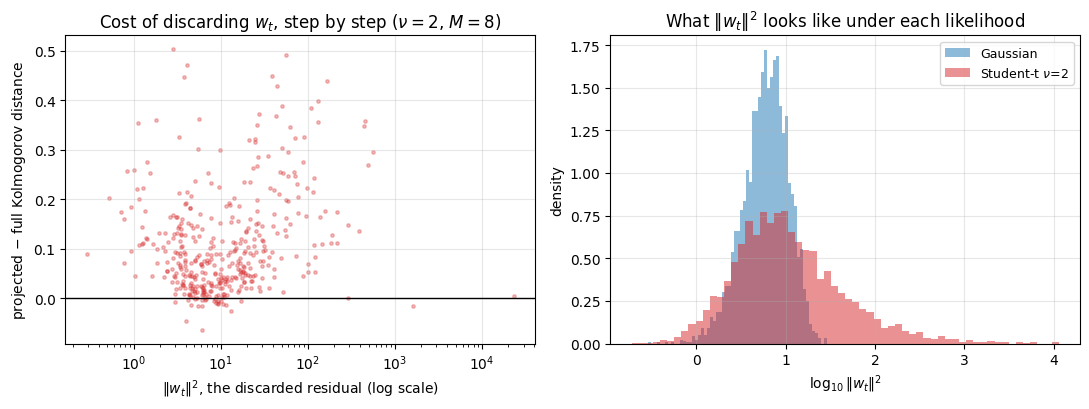

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].scatter(w2, dks, s=6, alpha=0.3, color="tab:red")
ax[0].set_xscale("log")
ax[0].axhline(0.0, color="k", lw=1.0)
ax[0].set_xlabel(r"$\|w_t\|^2$, the discarded residual (log scale)")
ax[0].set_ylabel("projected $-$ full Kolmogorov distance")
ax[0].set_title(rf"Cost of discarding $w_t$, step by step ($\nu={NU_LOOK}$, $M={M_LOOK}$)")

for lab, pot_i, col in (("Gaussian", gauss, "tab:blue"),
                        (rf"Student-t $\nu$={NU_LOOK}", pot, "tab:red")):
    xg, yg = om.simulate_obs_model(fn, pot_i, Sigma, T=4000, b=B, Q=Q, seed=7)
    _, wi = proj["split"](yg)
    ax[1].hist(np.log10(np.sum(wi ** 2, axis=1) + 1e-12), bins=60, alpha=0.5,
               color=col, label=lab, density=True)
ax[1].set_xlabel(r"$\log_{10}\|w_t\|^2$")
ax[1].set_ylabel("density")
ax[1].set_title(r"What $\|w_t\|^2$ looks like under each likelihood")
ax[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

**Conclusion of Section 6.** The information in $w_t$ is about *trust*, not about the state.

At $M = 8$ and $\nu = 2$, splitting the run by how large the discarded residual is:

| steps | full KS | projected KS | excess |
|---|---|---|---|
| quiet ($\|w_t\|^2$ below median) | $0.0486$ | $0.1397$ | $0.0911$ |
| wild (top $10\%$ of $\|w_t\|^2$) | $0.0349$ | $0.2250$ | $\mathbf{0.1901}$ |

The excess **doubles** on the wild steps, and the correlation of the per-step excess with
$\log\|w_t\|^2$ is $+0.216$.

The more telling column is the first. On exactly those steps where the discarded residual is large,
the **full** filter does *better* than its own average ($0.0349$ against $0.0486$), while the
projected filter does much worse ($0.2250$). A large $\|w_t\|^2$ means the $M$ coordinates disagree
with each other, which under a shared-scale Student-t is the signature of an outlying observation.
The full filter can see that and discount the observation accordingly; the projected filter has
thrown away the evidence and takes a corrupted $\hat z_t$ at face value.

So $w_t$ is orthogonal to the observation space and carries no information about $x_t$ — that much
is geometry — but it tells the filter **how much to believe $\hat z_t$**, and under a heavy-tailed
likelihood that is worth a great deal. The second panel shows why the Gaussian case can afford to
ignore it: there $\|w_t\|^2$ has a tight distribution with nothing to learn from, whereas under
$\nu = 2$ it is spread over orders of magnitude.

---
## Section 7 — Summary

### What this notebook was for

Part 2 claimed that more observations make the particle filter worse. Dr Gerber pointed out that
under a Gaussian likelihood this model reduces the $M$-dimensional observation to a $d$-dimensional
one, so the experiment could not have been testing that. The claim was withdrawn. This notebook
builds the setting where it *is* testable — a Student-t likelihood, where the reduction fails — and
tests it.

### The answer, in three parts

**1. Extra observation coordinates are not harmful, even under a Student-t.** Holding the total
observation precision fixed so that every $M$ poses an identical filtering problem — verified
exactly: the posterior spread is $0.78593$ at $M = 1, 2, 4, 8$ and $16$ — the mean Kolmogorov
distance is flat for the Gaussian ($0.0459 \to 0.0447$), for $\nu = 5$ ($0.0444 \to 0.0433$) and
for the Cauchy ($0.0436 \to 0.0433$). At $\nu = 1$ the cloud gets *healthier* with $M$. **The
natural reading of the withdrawn sentence fails even where it can be tested.**

**2. What Part 2 actually saw was precision, exactly as the correction said.** Under Part 2's own
convention the effective sample size roughly halves as $M$ goes $1 \to 16$ — but by a factor of
$1.46$–$1.54$ for *every* likelihood from Cauchy to near-Gaussian. A mechanism indifferent to tail
weight is not about tails, and Section 3 shows it vanishes once precision is held fixed.

**3. The real consequence is that the projection stops being free.** Replacing $y_t$ by $\hat z_t$
costs nothing under a Gaussian — $1.000$, with the two filters agreeing to $2\times10^{-15}$ on
identical random numbers — and costs up to $4.73\times$ under a Cauchy. The cost is monotone in
both $\nu$ and $M$ across all twenty cells, and decays to $1.162$, $1.020$, $1.008$, $1.000$ along
$\nu = 30, 100, 1000, \infty$. **This is the testable content of the original intuition, and it
holds.**

### Why it holds

$w_t$ is orthogonal to the observation space, so it says nothing about $x_t$. Under a shared-scale
Student-t it says something else: whether this observation is an outlier. On steps with the largest
$\|w_t\|^2$ the full filter beats its own average ($0.0349$ against $0.0486$) while the projected
filter collapses ($0.2250$). The discarded component is not information about the state, it is
**information about how far to trust the information about the state** — which a Gaussian
likelihood has no use for, and a heavy-tailed one does.

### Honest limits

- $d = 1$ throughout, because the exact benchmark is a one-dimensional grid filter. The mechanism
  is dimension-agnostic, but it has not been checked at $d > 1$.
- $f(x) = [x, \dots, x]$ only — a deliberately linear image, so that the potential shape is the
  only thing that can break the reduction. Curved images break it as well, and independently;
  that is Part 8.
- The joint Student-t shares one scale across coordinates, which is what makes $\|w_t\|^2$
  informative. `observation_models.py` also provides the independent-per-coordinate version, where
  the mechanism should be weaker. That comparison is not run here.
- $\rho(F) = 1$ (random walk) throughout, matching the model on the whiteboard. The stable case is
  not swept.